In [1]:
source("../chronopack/R/tradeseq_helpers.R")
load_chronopack_tradeseq_libraries()
set_tradeseq_workdir("../intmd/sc_to_tradeSeq/")


Loading required package: SummarizedExperiment

Loading required package: MatrixGenerics

Loading required package: matrixStats


Attaching package: 'MatrixGenerics'


The following objects are masked from 'package:matrixStats':

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,
    rowCumsums, rowDiffs, rowIQRDiffs, rowIQRs, rowLogSumExps,
    rowMadDiffs, rowMads, rowMaxs, rowMeans2, rowMedians, rowMins,
    rowOrderStats, rowProds, rowQuantiles, rowRanges

In [289]:
# ============== single-gene plot (flexible point color, ticks, time scaling) ==============
plot_tradeSeq_gene_pub_v2 <- function(
  gene, gamList, sce, counts_sub, PT, sizeFactors, cellWeights = NULL,
  q_by_gene = NULL,
  lineages   = NULL,
  nPoints    = 1000,
  colours    = NULL,
  lineage_labels = NULL,
  base_size = 18,
  title_size = 10,
  legend_size = 1.25,
  # NEW: point-color behavior
  color_points_by_lineage = FALSE,
  points_color = "#BBBBBB",
  points_alpha = 0.22,
  points_size  = 1.8,   # NEW: allow setting raw point size
  # NEW: spacing + axes
  inner_pad_pt = 6,
  time_max = NULL,          # e.g., 120 (minutes). If NULL, show pseudotime.
  nx_ticks = 5,
  ny_ticks = 5,
  ylim = NULL
) {
  stopifnot(gene %in% rownames(counts_sub))
  gm <- gamList[[gene]]

  dm <- SummarizedExperiment::colData(sce)$tradeSeq$dm
  t_cols <- grep("^t[0-9]+$", colnames(dm), value = TRUE)
  avail_lineages <- as.integer(sub("^t", "", t_cols))
  if (!length(avail_lineages)) stop("Could not find t1/t2/... columns in tradeSeq design (dm).")

  if (is.null(lineages)) lineages <- avail_lineages
  lineages <- intersect(lineages, avail_lineages)
  if (!length(lineages)) stop("Requested 'lineages' not present in dm.")

  ln_ids   <- lineages
  ln_codes <- paste0("L", ln_ids)
  if (is.null(lineage_labels)) {
    ln_labels <- ln_codes
  } else {
    stopifnot(length(lineage_labels) == length(lineages))
    ln_labels <- as.character(lineage_labels)
  }
  lab_map <- setNames(ln_labels, ln_ids)

  mk_lineage_vec <- function(ell, n) {
    lab <- unname(lab_map[as.character(ell)])
    factor(rep(lab, n), levels = ln_labels)
  }

  # reference library size
  sf_vec <- as.numeric(sizeFactors)
  s_ref  <- exp(mean(log(sf_vec), na.rm = TRUE))
  off_ref <- log(s_ref)

  # fitted curves
  fits <- lapply(ln_ids, function(ell) {
    df <- tradeSeq:::.getPredictRangeDf(dm, lineageId = ell, nPoints = nPoints)
    pr <- predict(gm, newdata = df, type = "link", se.fit = TRUE,
                  offset = rep(off_ref, nrow(df)))
    data.frame(
      lineage = mk_lineage_vec(ell, nrow(df)),
      t  = df[[paste0("t", ell)]],
      mu = log1p(exp(pr$fit)),
      lo = log1p(exp(pr$fit - 1.96 * pr$se.fit)),
      hi = log1p(exp(pr$fit + 1.96 * pr$se.fit))
    )
  })
  fit_all <- do.call(rbind, fits)

  # observed points normalized to s_ref
  y_cnt <- as.numeric(counts_sub[gene, ])
  y_cnt_norm <- y_cnt * (s_ref / sf_vec)
  get_pt_vec <- function(ell) if (is.matrix(PT)) as.numeric(PT[, ell]) else as.numeric(PT)

  # default cellWeights if missing
  if (is.null(cellWeights)) {
    cellWeights <- matrix(1, nrow = length(y_cnt_norm), ncol = max(avail_lineages))
    colnames(cellWeights) <- paste0("L", seq_len(ncol(cellWeights)))
  }

  # assign each cell to a lineage (argmax over selected lineages)
  cw_sub <- as.matrix(cellWeights[, ln_ids, drop = FALSE])
  cw_sub[!is.finite(cw_sub)] <- -Inf
  idx <- max.col(cw_sub, ties.method = "first")
  bad <- rowSums(cw_sub, na.rm = TRUE) <= 0
  idx[bad] <- NA_integer_
  lineage_obs <- factor(ifelse(is.na(idx), NA,
                               lab_map[as.character(ln_ids[idx])]),
                        levels = ln_labels)

  obs_all <- data.frame(
    pt = get_pt_vec(ln_ids[1]),
    y  = log1p(y_cnt_norm),
    lineage = lineage_obs
  )

  # weighted observed means per lineage
  wmean <- function(x, w) { s <- sum(w, na.rm = TRUE); if (is.finite(s) && s > 0) sum(x*w, na.rm=TRUE)/s else NA_real_ }
  obs_u_all <- lapply(ln_ids, function(ell) {
    pt_vec <- get_pt_vec(ell); w_col <- as.numeric(cellWeights[, ell])
    u_pt <- sort(unique(pt_vec))
    m_w <- vapply(u_pt, function(v) wmean(y_cnt_norm[pt_vec==v], w_col[pt_vec==v]), numeric(1))
    data.frame(
      lineage = mk_lineage_vec(ell, length(u_pt)),
      pt_mid  = u_pt,
      mean_norm_log1p = log1p(as.numeric(m_w))
    )
  })
  obs_u_all <- do.call(rbind, obs_u_all)

  # subtitle with FDR
  sub_txt <- NULL
  if (!is.null(q_by_gene) && gene %in% names(q_by_gene)) {
    qv <- unname(q_by_gene[gene]); if (is.finite(qv)) sub_txt <- paste0("FDR = ", formatC(qv, format="fg", digits=3))
  }

  # colors
  if (is.null(colours)) {
    base_cols <- c("#1b9e77", "#d95f02", "#7570b3", "#e7298a",
                   "#66a61e", "#e6ab02", "#a6761d", "#666666")
    colours <- rep(base_cols, length.out = length(ln_labels))
  } else {
    colours <- rep(colours, length.out = length(ln_labels))
  }
  names(colours) <- ln_labels
  fill_cols <- grDevices::adjustcolor(colours, alpha.f = 0.30)

  # legend size scalars
  lt  <- 12 * legend_size
  lx  <- 11 * legend_size
  lks <- grid::unit(12 * legend_size, "pt")
  lbm <- margin(l = 16 * legend_size, r = 16 * legend_size,
                t =  6 * legend_size, b =  6 * legend_size)

  # x-scale: map to minutes if time_max provided
  pt_min <- min(c(obs_all$pt, fit_all$t), na.rm = TRUE)
  pt_max <- max(c(obs_all$pt, fit_all$t), na.rm = TRUE)
  to_minutes <- function(x) (x - pt_min) / max(pt_max - pt_min, .Machine$double.eps) * time_max

  x_scale <- if (!is.null(time_max)) {
    scale_x_continuous(
      breaks = scales::pretty_breaks(n = nx_ticks),
      labels = function(x) round(to_minutes(x)),
      name   = "Time (min)"
    )
  } else {
    scale_x_continuous(
      breaks = scales::pretty_breaks(n = nx_ticks),
      name   = "Time"
    )
  }

  y_scale <- scale_y_continuous(breaks = scales::pretty_breaks(n = ny_ticks), name = "")

  # NEW: auto ylim if NULL (captures both curves and lo/hi ribbons)
  if (is.null(ylim)) {
    ylo <- suppressWarnings(min(fit_all$lo, na.rm = TRUE))
    yhi <- suppressWarnings(max(fit_all$hi, na.rm = TRUE))
    if (is.finite(ylo) && is.finite(yhi)) {
      pad <- 0.04 * (yhi - ylo)
      if (!is.finite(pad) || pad == 0) pad <- 0.2
      ylim <- c(max(0, ylo - pad), (yhi + pad)*1.25)
    }
  }

  # ------------------ build plot ------------------
  p <- ggplot()

  if (isTRUE(color_points_by_lineage)) {
    p <- p +
      geom_point(data = subset(obs_all, !is.na(lineage)),
                 aes(pt, y, colour = lineage),
                 size = points_size, alpha = points_alpha) +
      geom_point(data = subset(obs_all, is.na(lineage)),
                 aes(pt, y),
                 size = points_size, alpha = 0.20, colour = "#BBBBBB")
  } else {
    p <- p +
      geom_point(data = obs_all, aes(pt, y),
                 size = points_size, alpha = points_alpha, colour = points_color)
  }

  p <- p +
    geom_ribbon(data = fit_all, aes(t, ymin = lo, ymax = hi, fill = lineage),
                alpha = 0.35, colour = NA) +
    geom_line(data = fit_all, aes(t, mu, colour = lineage),
              linewidth = 1.7) +
    geom_point(data = obs_u_all, aes(pt_mid, mean_norm_log1p, colour = lineage),
               shape = 21, fill = "white", size = 3.8, stroke = 1.0) +
    scale_colour_manual(values = colours, name = "Lineage") +
    scale_fill_manual(values = fill_cols,  name = "Lineage") +
    x_scale + y_scale +
    labs(title = gene, subtitle = sub_txt) +
    coord_cartesian(expand = FALSE, ylim = ylim) +
    theme_minimal(base_size = base_size) +
    theme(
      panel.grid.minor = element_blank(),
      panel.grid.major.x = element_line(colour = "grey88"),
      panel.grid.major.y = element_line(colour = "grey88"),
      axis.text  = element_text(colour = "black"),
      axis.title = element_text(colour = "black"),
      plot.title = element_text(size = title_size, face = "bold", hjust = 0, colour = "black"),
      plot.subtitle = element_text(size = 10, colour = "black"),
      legend.position = "right",
      legend.title = element_text(size = lt),
      legend.text  = element_text(size = lx),
      legend.key.size = lks,
      legend.box.margin = lbm,
      plot.margin = margin(inner_pad_pt, inner_pad_pt, inner_pad_pt, inner_pad_pt)
    )

  p
}



library(ggplot2)

plot_tradeSeq_gene_pub <- function(
  gene, gamList, sce, counts_sub, PT, sizeFactors, cellWeights = NULL,
  q_by_gene = NULL,
  lineages   = NULL,
  omit_points = FALSE,
  nPoints    = 1000,
  colours    = NULL,
  lineage_labels = NULL,

  time_max = NULL,
  time_unit = "min",

  axis_text_size  = 14,
  axis_title_size = 16,

  # NEW: if NULL and time_max is set, defaults to seq(0, time_max, by = x_tick_step)
  x_tick_labels   = NULL,
  x_tick_step     = 20,

  # NEW: y tick density (like v2)
  ny_ticks = 5,

  show_title  = TRUE,
  show_legend = TRUE,

  # NEW: raw-point controls (match v2)
  color_points_by_lineage = FALSE,
  points_color = "#274C77",
  points_alpha = 0.35,
  points_size  = 1.8,

  # NEW: ylim controls (match v2 style; NULL => auto)
  ylim = NULL,

  save_pdf    = FALSE,
  pdf_filename = NULL,
  pdf_width   = 4,
  pdf_height  = 4
) {
  stopifnot(gene %in% rownames(counts_sub))
  gm <- gamList[[gene]]

  dm <- SummarizedExperiment::colData(sce)$tradeSeq$dm
  t_cols <- grep("^t[0-9]+$", colnames(dm), value = TRUE)
  avail_lineages <- as.integer(sub("^t", "", t_cols))
  if (length(avail_lineages) == 0L)
    stop("Could not find t1/t2/... columns in tradeSeq design (dm).")

  ## ---- choose which lineages to plot -----------------------------------
  if (is.null(lineages)) {
    lineages <- avail_lineages
  } else {
    lineages <- as.integer(lineages)
    lineages <- intersect(lineages, avail_lineages)
  }
  if (!length(lineages))
    stop("Requested 'lineages' not present in dm.")

  # legend labels
  lineage_codes <- paste0("L", lineages)
  if (is.null(lineage_labels)) {
    lineage_labels <- lineage_codes
  } else {
    if (length(lineage_labels) != length(lineages))
      stop("'lineage_labels' must have same length as 'lineages'.")
    lineage_labels <- as.character(lineage_labels)
  }
  lab_map <- setNames(lineage_labels, lineage_codes)

  # library size / offset
  sf_vec <- as.numeric(sizeFactors)
  s_ref  <- exp(mean(log(sf_vec), na.rm = TRUE))
  off_ref <- log(s_ref)

  # fitted curves
  fits <- lapply(lineages, function(ell) {
    df <- tradeSeq:::.getPredictRangeDf(dm, lineageId = ell, nPoints = nPoints)
    pr <- predict(gm, newdata = df, type = "link", se.fit = TRUE,
                  offset = rep(off_ref, nrow(df)))
    lab <- unname(lab_map[paste0("L", ell)])
    data.frame(
      lineage = factor(rep(lab, nrow(df)), levels = lineage_labels),
      t  = df[[paste0("t", ell)]],
      mu = log1p(exp(pr$fit)),
      lo = log1p(exp(pr$fit - 1.96 * pr$se.fit)),
      hi = log1p(exp(pr$fit + 1.96 * pr$se.fit))
    )
  })
  fit_all <- do.call(rbind, fits)

  # observed points normalized to s_ref
  y_cnt <- as.numeric(counts_sub[gene, ])
  y_cnt_norm <- y_cnt * (s_ref / sf_vec)
  get_pt_vec <- function(ell) if (is.matrix(PT)) as.numeric(PT[, ell]) else as.numeric(PT)

  # default cellWeights if missing
  if (is.null(cellWeights)) {
    cellWeights <- matrix(1, nrow = length(y_cnt_norm), ncol = max(avail_lineages))
    colnames(cellWeights) <- paste0("L", seq_len(ncol(cellWeights)))
  }

  # scatter points use pseudotime of the first selected lineage
  obs_all <- data.frame(
    pt = get_pt_vec(lineages[1]),
    y  = log1p(y_cnt_norm)
  )

  # if coloring points by lineage, assign each cell to a lineage (argmax over selected lineages)
  if (isTRUE(color_points_by_lineage) && !omit_points) {
    cw_sub <- as.matrix(cellWeights[, lineages, drop = FALSE])
    cw_sub[!is.finite(cw_sub)] <- -Inf
    idx <- max.col(cw_sub, ties.method = "first")
    bad <- rowSums(cw_sub, na.rm = TRUE) <= 0
    idx[bad] <- NA_integer_

    lab_by_id <- setNames(unname(lab_map[paste0("L", lineages)]), lineages)
    obs_all$lineage <- factor(
      ifelse(is.na(idx), NA, lab_by_id[as.character(lineages[idx])]),
      levels = lineage_labels
    )
  }

  # weighted observed means per lineage
  wmean <- function(x, w) {
    s <- sum(w, na.rm = TRUE)
    if (is.finite(s) && s > 0) sum(x*w, na.rm=TRUE)/s else NA_real_
  }
  obs_u_all <- lapply(lineages, function(ell) {
    pt_vec <- get_pt_vec(ell)
    w_col  <- as.numeric(cellWeights[, ell])
    u_pt   <- sort(unique(pt_vec))
    m_w    <- vapply(u_pt, function(v) wmean(y_cnt_norm[pt_vec==v], w_col[pt_vec==v]), numeric(1))
    lab <- unname(lab_map[paste0("L", ell)])
    data.frame(
      lineage = factor(rep(lab, length(u_pt)), levels = lineage_labels),
      pt_mid  = u_pt,
      mean_norm_log1p = log1p(as.numeric(m_w))
    )
  })
  obs_u_all <- do.call(rbind, obs_u_all)

  # subtitle with FDR
  sub_txt <- NULL
  if (!is.null(q_by_gene) && gene %in% names(q_by_gene)) {
    qv <- unname(q_by_gene[gene])
    if (is.finite(qv)) sub_txt <- paste0("FDR = ", formatC(qv, format = "fg", digits = 3))
  }

  # colors
  if (is.null(colours)) {
    base_cols <- c("#1b9e77", "#d95f02", "#7570b3", "#e7298a",
                   "#66a61e", "#e6ab02", "#a6761d", "#666666")
    colours <- rep(base_cols, length.out = length(lineage_labels))
  } else {
    colours <- rep(colours, length.out = length(lineage_labels))
  }
  names(colours) <- lineage_labels
  fill_cols <- grDevices::adjustcolor(colours, alpha.f = 0.30)

  legend_pos <- if (show_legend) "right" else "none"

  # ---- auto ylim if NULL: include points + lineage means + fitted lo/hi (matches your desired look)
    if (is.null(ylim)) {
      ylo <- suppressWarnings(min(fit_all$lo, na.rm = TRUE))
      yhi <- suppressWarnings(max(fit_all$hi, na.rm = TRUE))
    
      # (optional) also ensure the lineage mean dots fit
      ylo2 <- suppressWarnings(min(obs_u_all$mean_norm_log1p, na.rm = TRUE))
      yhi2 <- suppressWarnings(max(obs_u_all$mean_norm_log1p, na.rm = TRUE))
      ylo <- min(ylo, ylo2, na.rm = TRUE)
      yhi <- max(yhi, yhi2, na.rm = TRUE)
    
      if (is.finite(ylo) && is.finite(yhi)) {
        pad <- 0.04 * (yhi - ylo)
        if (!is.finite(pad) || pad == 0) pad <- 0.2
        ylim <- c(max(0, ylo - pad), 1.3 * (yhi + pad))  # <-- your old style
      } else {
        ylim <- c(0, 1)
      }
    }


  # y scale: show expression ticks (no limits here to avoid dropping points)
  # y_scale <- scale_y_continuous(
  #   breaks = scales::pretty_breaks(n = ny_ticks),
  #   name = "Expression"
  # )

    y_scale <- scale_y_continuous(
      breaks = scales::pretty_breaks(n = ny_ticks),
      labels = function(x) {
        ifelse(is.finite(x) & abs(x - round(x)) < 1e-9,
               formatC(x, format = "f", digits = 1),
               formatC(x, format = "fg", digits = 3))
      },
      name = "Expression"
    )

  # build plot
  p <- ggplot()

  if (!omit_points) {
    if (isTRUE(color_points_by_lineage)) {
      p <- p +
        geom_point(data = subset(obs_all, !is.na(lineage)),
                   aes(pt, y, colour = lineage),
                   size = points_size, alpha = points_alpha) +
        geom_point(data = subset(obs_all, is.na(lineage)),
                   aes(pt, y),
                   size = points_size, alpha = points_alpha, colour = "#BBBBBB")
    } else {
      p <- p +
        geom_point(data = obs_all, aes(pt, y),
                   size = points_size, alpha = points_alpha, colour = points_color)
    }
  }

  p <- p +
    geom_ribbon(data = fit_all,
                aes(t, ymin = lo, ymax = hi, fill = lineage),
                alpha = 0.35, colour = NA) +
    geom_line(data = fit_all,
              aes(t, mu, colour = lineage),
              linewidth = 1.7) +
    geom_point(data = obs_u_all,
               aes(pt_mid, mean_norm_log1p, colour = lineage),
               shape = 21, fill = "white", size = 3.8, stroke = 1.0) +
    scale_colour_manual(values = colours, name = "Lineage") +
    scale_fill_manual(values = fill_cols,  name = "Lineage") +
    y_scale +
    coord_cartesian(expand = FALSE, ylim = ylim) +
    theme_minimal(base_size = axis_text_size) +
    theme(
      panel.grid.minor = element_blank(),
      panel.grid.major.x = element_line(colour = "grey88"),
      panel.grid.major.y = element_line(colour = "grey88"),
      axis.text  = element_text(colour = "black", size = axis_text_size),
      axis.title = element_text(colour = "black", size = axis_title_size),
      plot.title = element_text(face = "bold", hjust = 0, colour = "black"),
      plot.subtitle = element_text(size = axis_text_size, colour = "black"),
      legend.position = legend_pos
    )

  # titles
  title_val    <- if (show_title) gene    else NULL
  subtitle_val <- if (show_title) sub_txt else NULL

  # x-axis labeling: convert 0..1 to 0..time_max if provided
  if (!is.null(time_max)) {
    stopifnot(is.numeric(time_max), length(time_max) == 1, is.finite(time_max), time_max > 0)

    if (is.null(x_tick_labels)) {
      x_tick_labels <- seq(0, time_max, by = x_tick_step)
    }

    br_time <- x_tick_labels
    br_pt   <- br_time / time_max
    keep    <- br_pt >= 0 & br_pt <= 1
    br_time <- br_time[keep]; br_pt <- br_pt[keep]

    x_title <- paste0("Time", if (!is.null(time_unit)) paste0(" (", time_unit, ")") else "")
    p <- p +
      scale_x_continuous(breaks = br_pt, labels = br_time, limits = c(0, 1)) +
      labs(title = title_val, subtitle = subtitle_val, x = x_title, y = "Expression")
  } else {
    p <- p +
      labs(
        title    = title_val,
        subtitle = subtitle_val,
        x = "Pseudotime",
        y = "log(normalized count + 1) @ reference library size"
      )
  }

  # optional PDF export
  if (save_pdf) {
    if (is.null(pdf_filename)) pdf_filename <- paste0(gene, "_tradeSeq.pdf")
    ggplot2::ggsave(filename = pdf_filename, plot = p,
                    width = pdf_width, height = pdf_height, units = "in")
  }

  return(p)
}

# ============== panel wrapper (size, spacing, ticks passed through) ==============
plot_tradeSeq_panel <- function(
  genes,
  gamList, sce, counts_sub, PT,
  sizeFactors, sizefactors = NULL,
  cellWeights = NULL, q_by_gene = NULL,
  lineages = NULL, nPoints = 1000, colours = NULL,
  lineage_labels = NULL,
  base_size = 18,
  title_size = 10,
  legend_size = 1.25,
  # NEW controls
  color_points_by_lineage = FALSE,
  points_color = "#BBBBBB",
  points_alpha = 0.22,
  points_size  = 1.8,   # NEW: pass-through
  inner_pad_pt = 6,
  panel_outer_pad_pt = 2,   # outer margin around the whole patchwork
  time_max = NULL,
  nx_ticks = 5,
  ny_ticks = 5,
  ylim = NULL,          # NEW: pass-through; NULL -> auto per gene
  ncol = 3,
  width = NULL, height = NULL, dpi = 300,
  save_path = NULL
) {
  if (missing(sizeFactors) && !is.null(sizefactors)) sizeFactors <- sizefactors
  if (is.function(sizeFactors))
    stop("You passed a function (likely DESeq2::sizeFactors). Provide the numeric vector used in fitGAM.")
  if (!is.numeric(sizeFactors) || length(sizeFactors) != ncol(counts_sub))
    stop("sizeFactors must be numeric, length ncol(counts_sub).")

  if (!is.null(width) && !is.null(height)) {
    local_options(list(repr.plot.width = width, repr.plot.height = height))
  }

  pls <- lapply(genes, function(g) {
    if (!g %in% rownames(counts_sub)) { warning(sprintf("Skipping '%s': not found in counts_sub", g)); return(NULL) }
    plot_tradeSeq_gene_pub_v2(
      gene = g,
      gamList = gamList, sce = sce, counts_sub = counts_sub,
      PT = PT, sizeFactors = sizeFactors, cellWeights = cellWeights,
      q_by_gene = q_by_gene, lineages = lineages, nPoints = nPoints,
      colours = colours, lineage_labels = lineage_labels,
      base_size = base_size, title_size = title_size, legend_size = legend_size,
      color_points_by_lineage = color_points_by_lineage,
      points_color = points_color, points_alpha = points_alpha,
      points_size = points_size,
      inner_pad_pt = inner_pad_pt,
      time_max = time_max, nx_ticks = nx_ticks, ny_ticks = ny_ticks,
      ylim = ylim
    )
  })
  pls <- Filter(Negate(is.null), pls)
  if (!length(pls)) stop("No valid genes to plot.")

  # panel legend sizing (same scale)
  lt  <- 12 * legend_size
  lx  <- 11 * legend_size
  lks <- grid::unit(12 * legend_size, "pt")
  lbm <- margin(l = 18 * legend_size, r = 18 * legend_size,
                t =  8 * legend_size, b =  8 * legend_size)

  panel <- wrap_plots(pls, ncol = ncol, guides = "collect") &
    theme(
      legend.position   = "right",
      legend.title      = element_text(size = lt),
      legend.text       = element_text(size = lx),
      legend.key.size   = lks,
      legend.box.margin = lbm,
      plot.margin       = margin(panel_outer_pad_pt, panel_outer_pad_pt,
                                 panel_outer_pad_pt, panel_outer_pad_pt)
    )

  if (!is.null(save_path)) {
    if (is.null(width) || is.null(height))
      stop("Provide 'width' and 'height' (inches) with save_path.")
    ggsave(save_path, panel, width = width, height = height, dpi = dpi)
  }

  panel
}

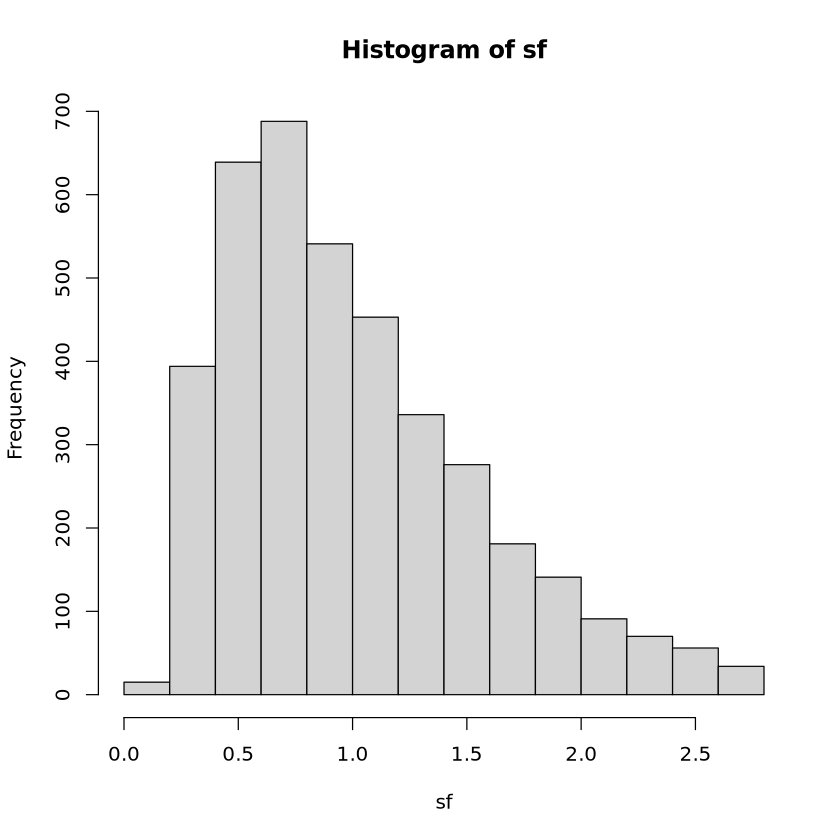

In [3]:
inputs <- read_tradeseq_inputs(tag = "")
counts <- inputs$counts
ct <- inputs$cell_times
libs_full <- inputs$libs_full
time_vec <- inputs$time_vec
lib_full <- inputs$lib_full
genes_sub <- inputs$subset_genes
genes_keep <- inputs$genes_keep
counts_sub <- inputs$counts_sub
sf <- inputs$sf

hist(sf)
dim(counts_sub)

cell_types <- read.csv("cell_types.csv", row.names = 1, check.names = FALSE)


In [28]:
hard_lineages <- prepare_hard_lineages(counts_sub, time_vec, sf, cell_type_path = "cell_types.csv")
PT <- hard_lineages$PT
PT_mat <- hard_lineages$PT_mat
CW <- hard_lineages$CW
CWz <- hard_lineages$CWz
cell_types <- hard_lineages$cell_types
ct <- hard_lineages$aligned_cell_types
offset_mat <- hard_lineages$offset_mat


In [32]:
head(CW)
table(ct$cell_type)


,K562,THP1
N701_TGAGACCACTGT-K562,1,0
N701_GGTCATGCTCGT-K562,1,0
N701_CGCGAGATCTCT-K562,1,0
N701_GCCAATATGCTT-K562,1,0
N701_AGAGCACAGGCG-K562,1,0
N701_GCTTGAAGAGTC-K562,1,0



K562 THP1 
3128  787 

In [33]:
# PT_mat, CWz, and offset_mat are created by prepare_hard_lineages().


In [34]:
dim(counts_sub)
dim(PT_mat)
dim(CWz)


[1] 13863  3915

[1] 3915    2

[1] 3915    2

In [35]:
# offset_mat is created by prepare_hard_lineages().


In [ ]:
sce <- fit_tradeseq_sce(
  counts_sub = counts_sub,
  pseudotime = PT_mat,
  cell_weights = CWz,
  offset_mat = offset_mat,
  nknots = 4,
  workers = 4,
  verbose = TRUE
)

saveRDS(sce, file = "sce.nknots4.rds")


In [293]:
asso_df <- association_df_multilineage(sce, n_points = 9)

sum(is.na(asso_df$waldStat_1))
sum(is.na(asso_df$waldStat_2))
sum(is.na(asso_df$waldStat_1) & is.na(asso_df$waldStat_2))


[1] 111

[1] 154

[1] 10

In [294]:
sig_genes <- significant_multilineage(asso_df, q_threshold = 0.01)
sig_df <- asso_df[sig_genes, , drop = FALSE]


In [298]:
write.csv(asso_df, 'asso_df.both.2trajectory.nknots4.expanded.csv', row.names = TRUE)
write.csv(sig_df, 'sig_df.both.2trajectory.nknots4.expanded.csv', row.names = TRUE)

In [ ]:
gamList <- fit_tradeseq_gamlist(
  counts_sub = counts_sub,
  pseudotime = PT_mat,
  cell_weights = CWz,
  offset_mat = offset_mat,
  nknots = 8,
  workers = 4,
  verbose = TRUE
)

saveRDS(gamList, file = "gamList.knots8.rds")


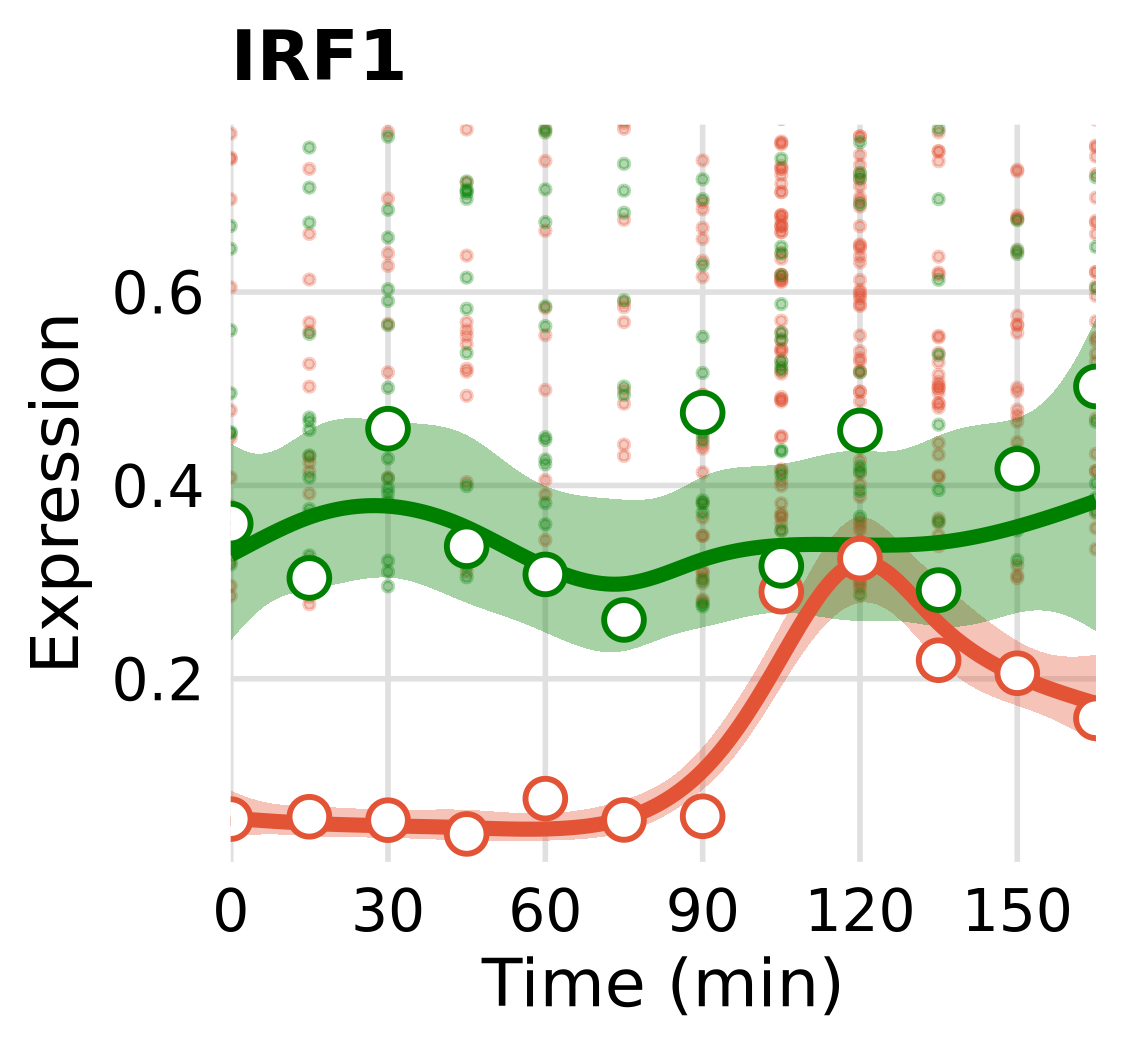

In [299]:
options(repr.plot.width = 3.75, repr.plot.height = 3.5, repr.plot.res = 300)

plot_tradeSeq_gene_pub(
  "IRF1", gamList, sce, counts_sub, PT_mat, sf,
  cellWeights = CWz,
  lineages = c(1,2),
  colours = c("#E35335", "#008000"),
  time_max = 165,
  x_tick_step = 30,  
  color_points_by_lineage = TRUE,
  points_size = 0.75,
  points_alpha = 0.3,
  axis_text_size = 14,
  axis_title_size = 16,
  ylim = NULL,
  lineage_labels = c("K562", "THP1"),
  show_legend = FALSE,
  # save_pdf = TRUE
)

# Create volcano plot

In [318]:
# --- Pattern-only differences via centered trajectory contrasts ----------------
# Supports:
#   (1) lagging either lineage before comparison,
#   (2) restricting to the overlapped window after lag,
#   (3) optional trimming of that overlap by fraction or by absolute time,
#   (4) NEW: signed max |log2FC(t vs start)| on the selected window (analogous to signed_max_log2fc_start_many)
#
# Requires: sce2 (SingleCellExperiment used in fitGAM), gamList2 (fitGAM(..., sce=FALSE))
# Optional: sig_df2 (to define output order)

compute_pattern_only_metrics <- function(
  genes        = rownames(sig_df),
  lineages     = c(1, 2),     # the two lineage IDs to compare (t1/t2/...)
  nPoints      = 300,         # density of interpolation grid inside the chosen window
  eps          = 1e-8,        # numerical stabilizer for ratios
  # --- lag control (choose one) ---
  lag_bins     = NULL,        # e.g., c(L1 = 0, L2 = 3)  [bins]
  lag_time     = NULL,        # e.g., c(L2 = 0.75)       [time units]
  # --- window control (applied AFTER lag) ---
  use_overlap  = TRUE,        # restrict to intersection of the two (lagged) curves
  t_trim       = c(0, 1),     # fraction inside the overlap, e.g., c(0.1, 0.9)
  t_range      = NULL,        # absolute time window inside the overlap, c(t_min, t_max)
  pseudo_count = 0.1          # shrink knob (mean-count units), used for log2FC
) {
  stopifnot(length(lineages) == 2)
  if (is.null(genes) || !length(genes)) stop("No genes supplied / detected.")

  dm <- SummarizedExperiment::colData(sce)$tradeSeq$dm
  t_cols <- grep("^t[0-9]+$", colnames(dm), value = TRUE)
  avail  <- as.integer(sub("^t","", t_cols))
  if (!all(lineages %in% avail)) {
    stop("Requested 'lineages' not found in tradeSeq design (dm).")
  }
  L_names <- paste0("L", lineages)

  # Helper: median step size per lineage (for lag_bins -> time conversion)
  median_dt <- function(ell) {
    v <- dm[[paste0("t", ell)]]
    u <- sort(unique(v[is.finite(v)]))
    if (length(u) >= 2L) stats::median(diff(u)) else 0
  }
  dt_l <- setNames(vapply(lineages, median_dt, numeric(1)), L_names)

  # Build shift (time) for each lineage
  shift_time <- setNames(rep(0, 2), L_names)
  if (!is.null(lag_time) && !is.null(lag_bins)) {
    stop("Provide either 'lag_time' OR 'lag_bins', not both.")
  }
  if (!is.null(lag_time)) {
    lt <- lag_time
    if (is.null(names(lt))) names(lt) <- L_names[seq_along(lt)]
    lt <- lt[names(lt) %in% L_names]
    shift_time[names(lt)] <- as.numeric(lt)
  } else if (!is.null(lag_bins)) {
    lb <- lag_bins
    if (is.null(names(lb))) names(lb) <- L_names[seq_along(lb)]
    lb <- lb[names(lb) %in% L_names]
    if (length(lb)) shift_time[names(lb)] <- as.numeric(lb) * dt_l[names(lb)]
  }

  # Predict curves for a lineage; return (t, mu_log1p, mu_mean)
  predict_curves <- function(g, ell) {
    gm <- gamList[[g]]
    if (is.null(gm)) {
      return(list(t = rep(NA_real_, nPoints),
                  mu_log1p = rep(NA_real_, nPoints),
                  mu_mean  = rep(NA_real_, nPoints)))
    }
    newdf <- tradeSeq:::.getPredictRangeDf(dm, lineageId = ell, nPoints = nPoints)
    tvec  <- as.numeric(newdf[[paste0("t", ell)]])
    eta   <- as.numeric(predict(gm, newdata = newdf, type = "link", se.fit = FALSE))
    mu    <- exp(eta)  # mean on natural scale
    list(t = tvec, mu_log1p = log1p(mu), mu_mean = mu)
  }

  # Signed max |log2FC(t vs start)| on a window (analogous to signed_max_log2fc_start_many)
  signed_max_log2fc_from_start <- function(mu, pc) {
    if (!length(mu) || any(!is.finite(mu))) return(NA_real_)
    mu0 <- mu[1L]
    log2fc_series <- log2((mu + pc) / (mu0 + pc))
    log2fc_series[ which.max(abs(log2fc_series)) ]
  }

  pc <- max(0, as.numeric(pseudo_count))

  # Core work per gene: shift -> overlap -> optional subsetting -> interpolate -> metrics
  res_list <- lapply(genes, function(g) {
    c1 <- predict_curves(g, lineages[1])
    c2 <- predict_curves(g, lineages[2])

    if (any(!is.finite(c1$t)) || any(!is.finite(c2$t))) {
      return(c(shape_sd = NA, shape_l2 = NA, shape_amp = NA,
               mean_diff = NA, end_diff = NA, shape_ratio = NA,
               log2FC_t1 = NA, log2FC_t2 = NA, diff_log2FC = NA))
    }

    # Apply lag (in time units) to the x-axis only
    t1 <- c1$t + shift_time[[L_names[1]]]
    t2 <- c2$t + shift_time[[L_names[2]]]

    # Determine overlap (if requested)
    lo <- max(min(t1, na.rm = TRUE), min(t2, na.rm = TRUE))
    hi <- min(max(t1, na.rm = TRUE), max(t2, na.rm = TRUE))
    if (!isTRUE(use_overlap)) {
      lo <- max(min(t1, na.rm = TRUE), min(t2, na.rm = TRUE))
      hi <- min(max(t1, na.rm = TRUE), max(t2, na.rm = TRUE))
    }

    # Apply absolute range inside overlap
    if (!is.null(t_range) && length(t_range) == 2L && all(is.finite(t_range))) {
      lo <- max(lo, min(t_range))
      hi <- min(hi, max(t_range))
    }

    # Trim by fraction inside [lo, hi]
    if (length(t_trim) == 2L && is.finite(lo) && is.finite(hi) && hi > lo) {
      a <- max(0, min(1, t_trim[1]))
      b <- max(0, min(1, t_trim[2]))
      if (b < a) { tmp <- a; a <- b; b <- tmp }
      lo2 <- lo + (hi - lo) * a
      hi2 <- lo + (hi - lo) * b
      lo <- lo2; hi <- hi2
    }

    if (!is.finite(lo) || !is.finite(hi) || hi <= lo) {
      return(c(shape_sd = NA, shape_l2 = NA, shape_amp = NA,
               mean_diff = NA, end_diff = NA, shape_ratio = NA,
               log2FC_t1 = NA, log2FC_t2 = NA, diff_log2FC = NA))
    }

    # Common grid on the selected interval
    t_common <- seq(lo, hi, length.out = nPoints)

    # Interpolate both trajectories on that grid
    mu1_log1p <- approx(t1, c1$mu_log1p, xout = t_common, ties = "ordered")$y
    mu2_log1p <- approx(t2, c2$mu_log1p, xout = t_common, ties = "ordered")$y
    m1        <- approx(t1, c1$mu_mean,  xout = t_common, ties = "ordered")$y
    m2        <- approx(t2, c2$mu_mean,  xout = t_common, ties = "ordered")$y

    if (any(!is.finite(mu1_log1p)) || any(!is.finite(mu2_log1p)) ||
        any(!is.finite(m1))        || any(!is.finite(m2))) {
      return(c(shape_sd = NA, shape_l2 = NA, shape_amp = NA,
               mean_diff = NA, end_diff = NA, shape_ratio = NA,
               log2FC_t1 = NA, log2FC_t2 = NA, diff_log2FC = NA))
    }

    # ----- pattern-only contrasts on log1p(mean) scale over the selected window -----
    d         <- mu1_log1p - mu2_log1p
    mean_diff <- mean(d)
    end_diff  <- tail(d, 1)
    d_ctr     <- d - mean_diff

    shape_sd    <- stats::sd(d_ctr)
    shape_l2    <- sqrt(mean(d_ctr^2))
    shape_amp   <- max(abs(d_ctr))
    shape_ratio <- shape_sd / (abs(mean_diff) + eps)

    # ----- UPDATED: signed max |log2FC(t vs start)| on the selected window -----
    log2FC_t1    <- signed_max_log2fc_from_start(m1, pc)
    log2FC_t2    <- signed_max_log2fc_from_start(m2, pc)
    diff_log2FC  <- log2FC_t1 - log2FC_t2

    c(shape_sd = shape_sd,
      shape_l2 = shape_l2,
      shape_amp = shape_amp,
      mean_diff = mean_diff,
      end_diff  = end_diff,
      shape_ratio = shape_ratio,
      log2FC_t1 = log2FC_t1,
      log2FC_t2 = log2FC_t2,
      diff_log2FC = diff_log2FC)
  })

  out <- as.data.frame(do.call(rbind, res_list))
  rownames(out) <- genes

  # Preserve requested order if sig_df exists
  if (exists("sig_df")) {
    out <- out[rownames(sig_df), , drop = FALSE]
  }

  # convenient ranks (higher = more pattern-y)
  out$rank_shape_l2 <- rank(-out$shape_l2,    na.last = "keep", ties.method = "average")
  out$rank_shape_sd <- rank(-out$shape_sd,    na.last = "keep", ties.method = "average")
  out$rank_ratio    <- rank(-out$shape_ratio, na.last = "keep", ties.method = "average")

  out
}

# ---- Example usage ------------------------------------------------------------
# Compare L1 vs L2 after shifting L2 by +3 bins, then compute metrics on the overlap,
# trimmed to the middle 80% of that overlap.
pattern_only_tab2 <- compute_pattern_only_metrics(
  lineages    = c(1, 2),
  lag_bins    = c(L1 = 0, L2 = 3),   # or: lag_time = c(L2 = 0.75)
  use_overlap = TRUE,
  t_trim      = c(0.10, 0.90),
  pseudo_count = 0.1
)

# Inspect top pattern-only candidates and FC metrics (on the chosen window)
head(pattern_only_tab2[order(-pattern_only_tab2$shape_l2),
     c("shape_l2","shape_sd","shape_amp","mean_diff","end_diff",
       "shape_ratio","log2FC_t1","log2FC_t2","diff_log2FC")], 20)

# (Optional) Combine with an existing table, preserving order:
combined <- cbind(sig_df, pattern_only_tab2[rownames(sig_df), ])
head(combined)

,shape_l2,shape_sd,shape_amp,mean_diff,end_diff,shape_ratio,log2FC_t1,log2FC_t2,diff_log2FC
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
CCL4,0.7789037,0.7802051,1.2516338,-1.49420410,-2.7458379,0.5221543,0.52539149,4.6525626,-4.127171068
CCL4L2,0.7147617,0.7159559,1.1998544,-1.12754944,-2.3274039,0.6349663,0.47073959,4.5218742,-4.051134657
CCL3,0.6493165,0.6504014,1.0048187,-1.33100209,-2.2097926,0.4886554,0.36685094,4.0191305,-3.652279585
CXCL8,0.6035321,0.6045405,1.0128503,-0.89526640,-1.9081167,0.6752632,2.25131880,4.7622273,-2.510908476
TNFAIP2,0.5960893,0.5970853,1.0525900,-1.00672728,-2.0593173,0.5930954,0.82593914,3.8043527,-2.978413532
CCL3L3,0.5886043,0.5895878,0.9248973,-0.86023198,-1.7851293,0.6853823,0.27430491,4.1538770,-3.879572076
CXCL1,0.4941193,0.4949449,0.7872889,-0.55838878,-1.3456777,0.8863805,2.08185514,4.7850818,-2.703226676
TNFAIP3,0.4773611,0.4781587,0.7167030,-0.79144521,-1.5060979,0.6041589,1.21695218,3.6798538,-2.462901650
CXCL3,0.4448632,0.4456065,0.7111769,0.01116317,-0.6913893,39.9175326,2.73333797,4.5155224,-1.782184464


,waldStat,df,pvalue,waldStat_1,df_1,pvalue_1,waldStat_2,df_2,pvalue_2,meanLogFC,...,shape_amp,mean_diff,end_diff,shape_ratio,log2FC_t1,log2FC_t2,diff_log2FC,rank_shape_l2,rank_shape_sd,rank_ratio
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
GRB10,25.55952,6,2.688784e-04,22.99617,3,4.045730e-05,2.5633454,3,4.639518e-01,0.7587007,...,0.01955665,0.15086047,0.13130382,0.07552428,-0.32620274,-0.18375700,-0.14244574,622,622,606
REV3L,42.90778,6,1.216489e-07,19.43016,3,2.227458e-04,23.4776194,3,3.210748e-05,0.4867669,...,0.07206011,-0.25109234,-0.18858903,0.15547794,-0.29865839,-0.68355626,0.38489787,267,267,445
STAG2,29.71256,6,4.457541e-05,28.47977,3,2.880195e-06,1.2327958,3,7.451498e-01,0.1615874,...,0.03542063,-0.50489614,-0.52149473,0.03187755,-0.37474217,-0.05576369,-0.31897848,537,537,705
MYLIP,24.04404,6,5.126063e-04,23.89593,3,2.626136e-05,0.1481068,3,9.854967e-01,0.2521432,...,0.03127073,0.06452075,0.03538112,0.30020493,-0.52671994,-0.02332938,-0.50339057,492,492,256
HNRNPU,20.01629,6,2.750962e-03,19.71043,3,1.948869e-04,0.3058688,3,9.589210e-01,0.0362661,...,0.03209894,-0.22258070,-0.25467964,0.05533277,-0.06378041,-0.01190232,-0.05187809,610,610,639
NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,...,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA


In [319]:
saveRDS(combined, 'combined.rds')

,waldStat,df,pvalue,waldStat_1,df_1,pvalue_1,waldStat_2,df_2,pvalue_2,meanLogFC,...,shape_amp,mean_diff,end_diff,shape_ratio,log2FC_t1,log2FC_t2,diff_log2FC,rank_shape_l2,rank_shape_sd,rank_ratio
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
CCL3,611.6768,6,0,13.36376,3,0.003912486,598.313,3,0,1.477595,...,1.004819,-1.331002,-2.209793,0.4886554,0.3668509,4.019131,-3.65228,3,3,150


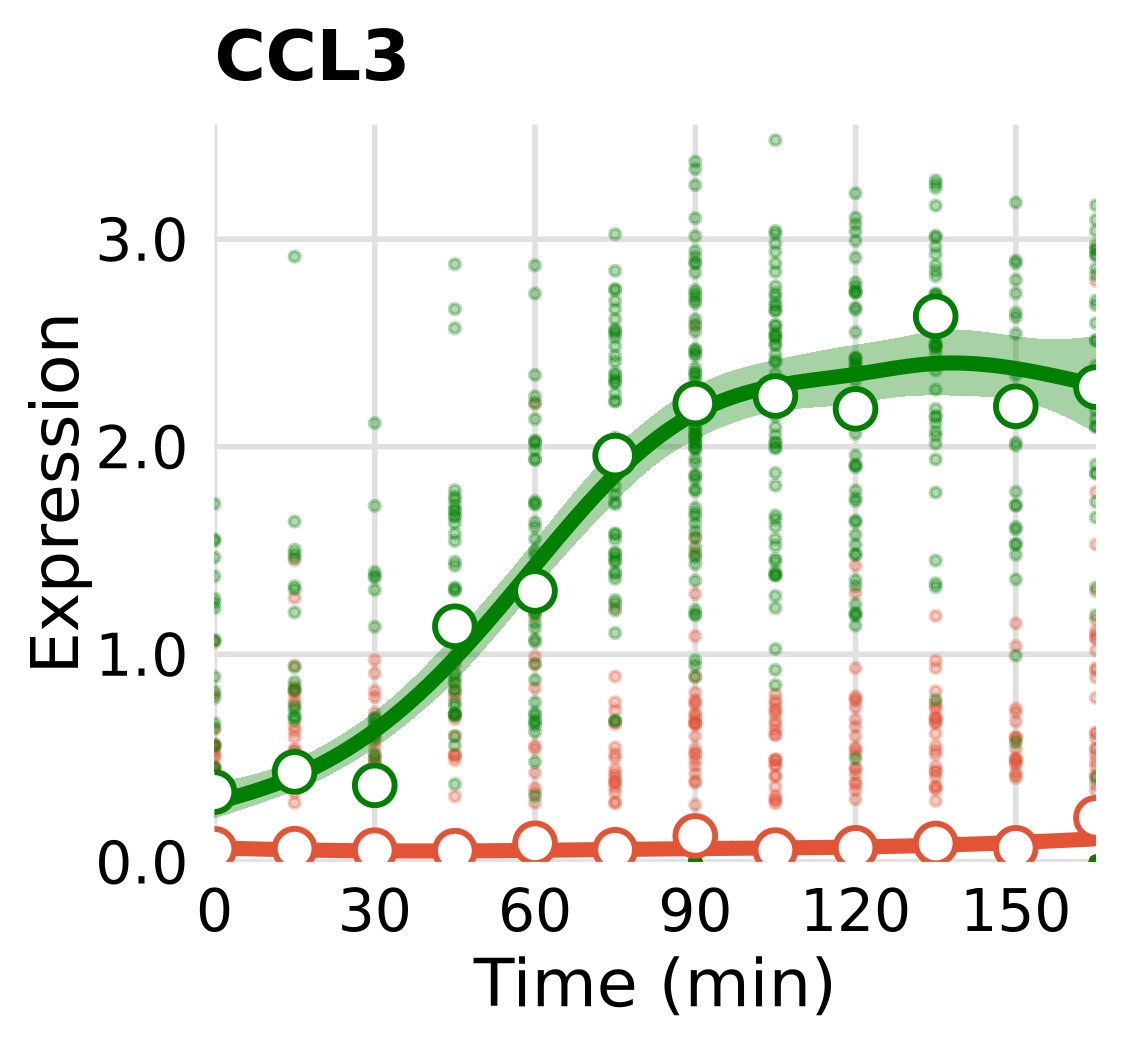

In [336]:
options(repr.plot.width = 3.75, repr.plot.height = 3.5, repr.plot.res = 300)

query_gene = 'CCL3'

plot_tradeSeq_gene_pub(
  query_gene, gamList, sce, counts_sub, PT_mat, sf,
  cellWeights = CWz,
  lineages = c(1,2),
  colours = c("#E35335", "#008000"),
  time_max = 165,
  x_tick_step = 30,  
  color_points_by_lineage = TRUE,
  points_size = 0.75,
  points_alpha = 0.3,
  axis_text_size = 14,
  axis_title_size = 16,
  ylim = NULL,
  # lineage_labels = c("K562", "THP1"),
  show_legend = FALSE,
  # save_pdf = TRUE
)

combined[query_gene,]

# Export tradeSeq fits at observed timepoints

In [333]:
# ===== Fast export at observed time points only ============================
# Outputs (all CSVs in `out_dir`):
#  - fits_at_obs.csv : gene, lineage, t, mu_log1p, lo_log1p, hi_log1p
#  - obs_weighted_means.csv : gene, lineage, pt_mid, mean_norm_log1p
#  - meta.csv : s_ref, lineages (exported), n_points_per_lineage (comma-separated)

export_tradeSeq_at_observed <- function(
  gamList,
  sce,
  counts_sub,            # genes x cells (raw counts)
  PT,                    # vector or matrix (cells x lineages)
  sizeFactors,           # length = ncol(counts_sub)
  cellWeights = NULL,    # matrix (cells x lineages); if NULL -> all ones
  genes       = intersect(names(gamList), rownames(counts_sub)),
  lineages    = NULL,    # e.g. c(1,2). NULL = all available in dm
  out_dir     = "ts_export_obs",
  q_by_gene   = NULL     # optional named numeric vector of FDRs
){
  stopifnot(all(genes %in% names(gamList)))
  dir.create(out_dir, showWarnings = FALSE, recursive = TRUE)

  # --- pull the design (dm) and discover lineages --------------------------
  dm <- tryCatch(S4Vectors::metadata(sce)$tradeSeq$dm, error = function(e) NULL)
  if (is.null(dm)) dm <- tryCatch(sce$tradeSeq$dm, error = function(e) NULL)
  if (is.null(dm)) stop("Could not find tradeSeq design matrix 'dm' in 'sce'.")

  t_cols <- grep("^t[0-9]+$", colnames(dm), value = TRUE)
  avail_lineages <- as.integer(sub("^t", "", t_cols))
  if (!length(avail_lineages)) stop("No t1/t2/... columns in dm.")

  if (is.null(lineages)) lineages <- avail_lineages
  lineages <- intersect(lineages, avail_lineages)
  if (!length(lineages)) stop("Requested 'lineages' not present in dm.")

  # --- reference library size & offset ------------------------------------
  sf_vec <- as.numeric(sizeFactors)
  s_ref  <- exp(mean(log(sf_vec), na.rm = TRUE))
  off_ref <- log(s_ref)

  # --- helpers --------------------------------------------------------------
  .get_pt_vec <- function(ell) if (is.matrix(PT)) as.numeric(PT[, ell]) else as.numeric(PT)
  if (is.null(cellWeights)) {
    cellWeights <- matrix(1, nrow = length(sf_vec), ncol = max(avail_lineages))
    colnames(cellWeights) <- paste0("L", seq_len(ncol(cellWeights)))
  }
  wmean <- function(x, w) {
    s <- sum(w, na.rm = TRUE)
    if (is.finite(s) && s > 0) sum(x * w, na.rm = TRUE) / s else NA_real_
  }

  # --- build newdata exactly at observed time points (once per lineage) ----
  u_pt_map <- list()     # list "L1" -> numeric vector of unique PTs
  nd_map   <- list()     # list "L1" -> data.frame for predict()
  npts_per <- integer(length(lineages))
  names(npts_per) <- paste0("L", lineages)

  for (ell in lineages) {
    u_pt <- sort(unique(.get_pt_vec(ell)))
    u_pt_map[[paste0("L", ell)]] <- u_pt
    npts_per[paste0("L", ell)] <- length(u_pt)

    # Create a correctly-shaped newdata, then overwrite the t_ell column
    nd <- tradeSeq:::.getPredictRangeDf(dm, lineageId = ell, nPoints = length(u_pt))
    nd[[paste0("t", ell)]] <- u_pt
    nd_map[[paste0("L", ell)]] <- nd
  }

  # --- accumulate results in memory (faster than appending to disk) --------
  fits_all   <- vector("list", length(genes) * length(lineages))
  wmeans_all <- vector("list", length(genes) * length(lineages))
  k <- 0L

  for (g in genes) {
    gm <- gamList[[g]]
    y_cnt <- as.numeric(counts_sub[g, ])
    y_cnt_norm <- y_cnt * (s_ref / sf_vec)

    for (ell in lineages) {
      key <- paste0("L", ell)
      nd  <- nd_map[[key]]
      u_pt <- u_pt_map[[key]]

      # predictions on the link scale at observed time points + SE
      pr <- predict(gm, newdata = nd, type = "link", se.fit = TRUE,
                    offset = rep(off_ref, nrow(nd)))
      k <- k + 1L
      fits_all[[k]] <- data.frame(
        gene     = g,
        lineage  = key,
        t        = u_pt,
        mu_log1p = log1p(exp(pr$fit)),
        lo_log1p = log1p(exp(pr$fit - 1.96 * pr$se.fit)),
        hi_log1p = log1p(exp(pr$fit + 1.96 * pr$se.fit)),
        check.names = FALSE
      )

      # weighted observed means at the same PTs (what the fit "sees")
      pt_vec <- .get_pt_vec(ell)
      w_col  <- as.numeric(cellWeights[, ell])
      m_w <- vapply(u_pt, function(v)
        wmean(y_cnt_norm[pt_vec == v], w_col[pt_vec == v]),
        numeric(1))
      wmeans_all[[k]] <- data.frame(
        gene   = g,
        lineage = key,
        pt_mid = u_pt,
        mean_norm_log1p = log1p(as.numeric(m_w)),
        check.names = FALSE
      )
    }
  }

  fits_all   <- do.call(rbind, fits_all)
  wmeans_all <- do.call(rbind, wmeans_all)

  # --- write once -----------------------------------------------------------
  path_fits   <- file.path(out_dir, "fits_at_obs.csv")
  path_wmeans <- file.path(out_dir, "obs_weighted_means.csv")
  write.csv(fits_all,   path_fits,   row.names = FALSE)
  write.csv(wmeans_all, path_wmeans, row.names = FALSE)

  meta <- data.frame(
    s_ref = s_ref,
    lineages = paste(lineages, collapse = ","),
    n_points_per_lineage = paste(paste0(names(npts_per), ":", npts_per), collapse = ";")
  )
  write.csv(meta, file.path(out_dir, "meta.csv"), row.names = FALSE)

  if (!is.null(q_by_gene)) {
    stopifnot(!is.null(names(q_by_gene)))
    write.csv(data.frame(gene = names(q_by_gene), q = as.numeric(q_by_gene)),
              file.path(out_dir, "q_by_gene.csv"), row.names = FALSE)
  }

  message("Wrote:\n  - ", path_fits,
          "\n  - ", path_wmeans,
          "\n  - ", file.path(out_dir, "meta.csv"),
          if (!is.null(q_by_gene)) paste0("\n  - ", file.path(out_dir, "q_by_gene.csv")) else "")
}

          
export_tradeSeq_at_observed(
  gamList     = gamList,
  sce         = sce,
  counts_sub  = counts_sub,
  PT          = PT_mat,       # or a vector if shared across lineages
  sizeFactors = sf,
  cellWeights = CWz,
  genes       = rownames(counts_sub),  # or a subset
  lineages    = c(1, 2),
  out_dir     = "ts_export_obs"
)

Wrote:
  - ts_export_obs/fits_at_obs.csv
  - ts_export_obs/obs_weighted_means.csv
  - ts_export_obs/meta.csv



In [340]:
# ===== Export tradeSeq fits on an arbitrary grid (NO observed means) =====
# Outputs (all CSVs in `out_dir`):
#  - fits_on_grid.csv : gene, lineage, pt, time, mu_log1p, lo_log1p, hi_log1p
#  - meta.csv : s_ref, lineages, grid_n, grid_mode, time_max, n_points_per_lineage
#  - q_by_gene.csv (optional): gene, q

export_tradeSeq_on_grid <- function(
  gamList,
  sce,
  counts_sub,            # genes x cells (raw counts) [kept only for gene universe checks]
  PT,                    # (unused here, but kept for signature compatibility)
  sizeFactors,           # length = ncol(counts_sub)
  cellWeights = NULL,    # (unused here, kept for signature compatibility)
  genes       = intersect(names(gamList), rownames(counts_sub)),
  lineages    = NULL,    # e.g. c(1,2). NULL = all available in dm
  out_dir     = "ts_export_grid",
  q_by_gene   = NULL,    # optional named numeric vector of FDRs

  # ----- grid spec -----
  grid_n      = 100,
  grid_pt     = NULL,          # optional explicit pt grid in [0,1]
  time_max    = NULL,          # if provided, export a "time" column; required if grid_mode="time"
  grid_mode   = c("pt", "time"),
  clamp_pt    = TRUE           # clamp pt into [0,1]
){
  grid_mode <- match.arg(grid_mode)

  stopifnot(length(genes) > 0)
  stopifnot(all(genes %in% names(gamList)))
  dir.create(out_dir, showWarnings = FALSE, recursive = TRUE)

  # --- pull dm (design) and discover lineages ------------------------------
  dm <- tryCatch(S4Vectors::metadata(sce)$tradeSeq$dm, error = function(e) NULL)
  if (is.null(dm)) dm <- tryCatch(sce$tradeSeq$dm, error = function(e) NULL)
  if (is.null(dm)) stop("Could not find tradeSeq design matrix 'dm' in 'sce'.")

  t_cols <- grep("^t[0-9]+$", colnames(dm), value = TRUE)
  avail_lineages <- as.integer(sub("^t", "", t_cols))
  if (!length(avail_lineages)) stop("No t1/t2/... columns in dm.")

  if (is.null(lineages)) lineages <- avail_lineages
  lineages <- intersect(as.integer(lineages), avail_lineages)
  if (!length(lineages)) stop("Requested 'lineages' not present in dm.")

  # --- reference library size & offset -------------------------------------
  sf_vec <- as.numeric(sizeFactors)
  if (length(sf_vec) != ncol(counts_sub)) {
    stop("sizeFactors must have length == ncol(counts_sub).")
  }
  s_ref   <- exp(mean(log(sf_vec), na.rm = TRUE))
  off_ref <- log(s_ref)

  # --- build grid -----------------------------------------------------------
  if (!is.null(grid_pt)) {
    pt_grid <- as.numeric(grid_pt)
  } else {
    if (grid_mode == "pt") {
      pt_grid <- seq(0, 1, length.out = grid_n)
    } else {
      if (is.null(time_max) || !is.finite(time_max) || time_max <= 0)
        stop("grid_mode='time' requires a positive numeric time_max.")
      time_grid <- seq(0, time_max, length.out = grid_n)
      pt_grid <- time_grid / time_max
    }
  }

  if (clamp_pt) pt_grid <- pmin(pmax(pt_grid, 0), 1)
  pt_grid <- sort(unique(pt_grid))
  grid_n_eff <- length(pt_grid)

  # time column for export (optional)
  time_grid <- if (!is.null(time_max) && is.finite(time_max) && time_max > 0) pt_grid * time_max else rep(NA_real_, grid_n_eff)

  # --- newdata per lineage (same grid for all lineages) ---------------------
  nd_map <- list()
  npts_per <- integer(length(lineages))
  names(npts_per) <- paste0("L", lineages)

  for (ell in lineages) {
    key <- paste0("L", ell)
    npts_per[key] <- grid_n_eff

    nd <- tradeSeq:::.getPredictRangeDf(dm, lineageId = ell, nPoints = grid_n_eff)
    nd[[paste0("t", ell)]] <- pt_grid
    nd_map[[key]] <- nd
  }

  # --- accumulate fits only -------------------------------------------------
  fits_all <- vector("list", length(genes) * length(lineages))
  k <- 0L

  for (g in genes) {
    gm <- gamList[[g]]

    for (ell in lineages) {
      key <- paste0("L", ell)
      nd  <- nd_map[[key]]

      pr <- predict(gm, newdata = nd, type = "link", se.fit = TRUE,
                    offset = rep(off_ref, nrow(nd)))

      k <- k + 1L
      fits_all[[k]] <- data.frame(
        gene     = g,
        lineage  = key,
        pt       = pt_grid,
        time     = time_grid,
        mu_log1p = log1p(exp(pr$fit)),
        lo_log1p = log1p(exp(pr$fit - 1.96 * pr$se.fit)),
        hi_log1p = log1p(exp(pr$fit + 1.96 * pr$se.fit)),
        check.names = FALSE
      )
    }
  }

  fits_all <- do.call(rbind, fits_all)
  write.csv(fits_all, file.path(out_dir, "fits_on_grid.csv"), row.names = FALSE)

  meta <- data.frame(
    s_ref = s_ref,
    lineages = paste(lineages, collapse = ","),
    grid_n = grid_n_eff,
    grid_mode = grid_mode,
    time_max = if (!is.null(time_max)) time_max else NA_real_,
    n_points_per_lineage = paste(paste0(names(npts_per), ":", npts_per), collapse = ";")
  )
  write.csv(meta, file.path(out_dir, "meta.csv"), row.names = FALSE)

  if (!is.null(q_by_gene)) {
    stopifnot(!is.null(names(q_by_gene)))
    write.csv(
      data.frame(gene = names(q_by_gene), q = as.numeric(q_by_gene)),
      file.path(out_dir, "q_by_gene.csv"),
      row.names = FALSE
    )
  }

  message("Wrote:\n  - ", file.path(out_dir, "fits_on_grid.csv"),
          "\n  - ", file.path(out_dir, "meta.csv"),
          if (!is.null(q_by_gene)) paste0("\n  - ", file.path(out_dir, "q_by_gene.csv")) else "")

  invisible(list(fits = fits_all, meta = meta))
}

# ---------------- Example usage ----------------
# 100 points spanning the full 2 hours (120 min), common grid for both lineages:
export_tradeSeq_on_grid(
  gamList     = gamList,
  sce         = sce,
  counts_sub  = counts_sub,
  PT          = PT_mat,   # unused but kept for signature compatibility
  sizeFactors = sf,
  genes       = rownames(counts_sub),
  lineages    = c(1, 2),
  out_dir     = "ts_export_grid_100pts",
  grid_mode   = "time",
  time_max    = 120,
  grid_n      = 100
)

Wrote:
  - ts_export_grid_100pts/fits_on_grid.csv
  - ts_export_grid_100pts/meta.csv

